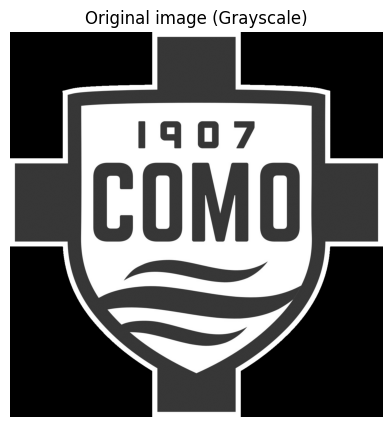

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def rgb_to_grayscale(rgb_img):
    if len(rgb_img.shape) == 3:
        r, g, b = rgb_img[:, :, 0], rgb_img[:, :, 1], rgb_img[:, :, 2]
        gray = 0.299 * r + 0.587 * g + 0.114 * b
        return gray.astype(np.uint8)
    return rgb_img

file_path = 'image.jpg'

raw_img = plt.imread(file_path)

if raw_img.dtype == np.float32 or raw_img.dtype == np.float64:
    raw_img = (raw_img * 255).astype(np.uint8)

original_img = rgb_to_grayscale(raw_img)

plt.figure(figsize=(5, 5))
plt.imshow(original_img, cmap='gray')
plt.title("Original image (Grayscale)")
plt.axis('off')
plt.show()

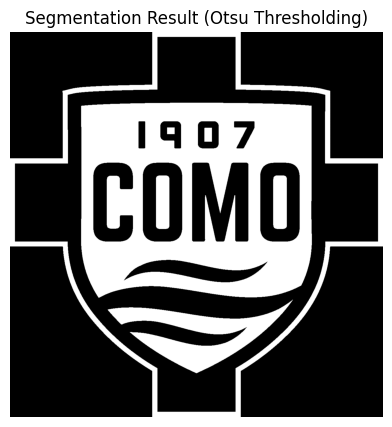

In [5]:
def manual_otsu_thresholding(image):
    height, width = image.shape
    total_pixels = height * width

    histogram = np.zeros(256)
    for r in range(height):
        for c in range(width):
            val = image[r, c]
            histogram[val] += 1

    prob = histogram / total_pixels

    max_variance = -1
    best_threshold = 0

    for t in range(256):
        w0 = np.sum(prob[:t])
        w1 = np.sum(prob[t:])

        if w0 == 0 or w1 == 0:
            continue

        mean0 = np.sum(np.arange(t) * prob[:t]) / w0
        mean1 = np.sum(np.arange(t, 256) * prob[t:]) / w1

        var_between = w0 * w1 * ((mean0 - mean1) ** 2)

        if var_between > max_variance:
            max_variance = var_between
            best_threshold = t

    binary_img = np.zeros_like(image, dtype=np.uint8)
    for r in range(height):
        for c in range(width):
            binary_img[r, c] = 1 if image[r, c] >= best_threshold else 0

    return binary_img

segmented_img = manual_otsu_thresholding(original_img)

plt.figure(figsize=(5, 5))
plt.imshow(segmented_img, cmap='gray')
plt.title("Segmentation Result (Otsu Thresholding)")
plt.axis('off')
plt.show()

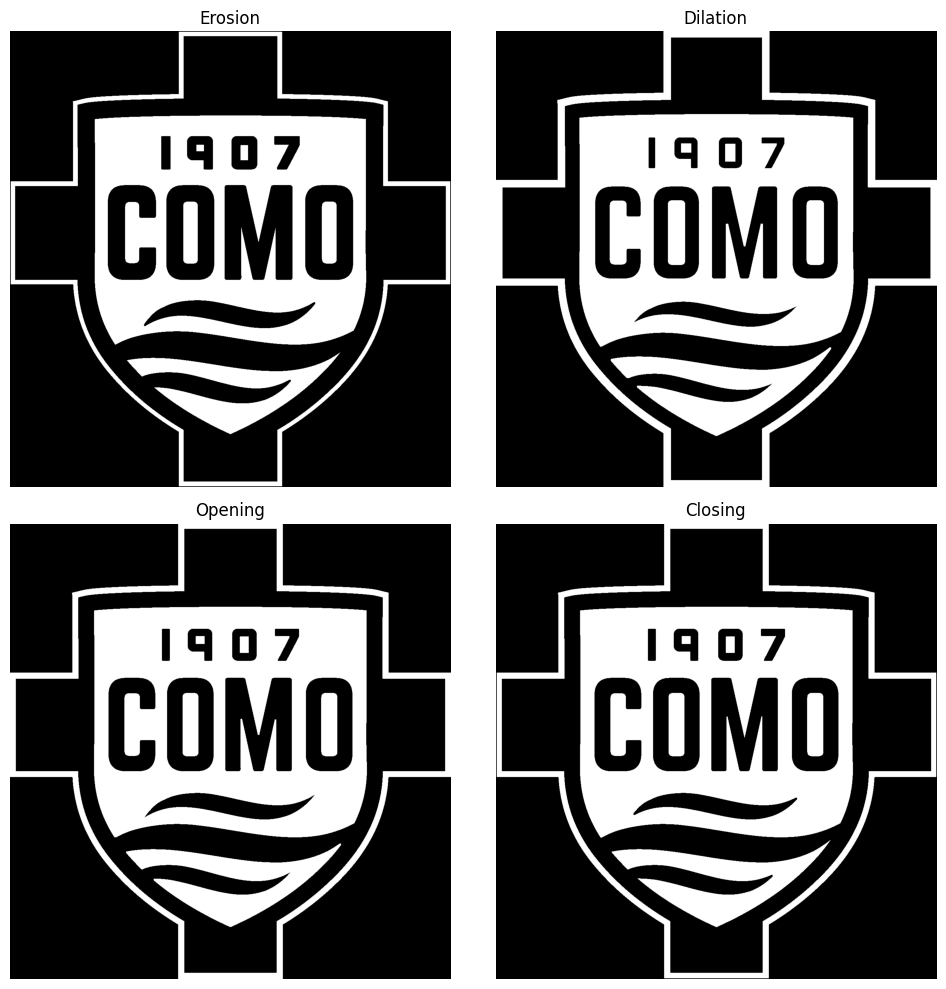

In [8]:
def get_structuring_element(shape='square', size=3):
    if shape == 'square':
        return np.ones((size, size), dtype=np.uint8)
    elif shape == 'cross':
        kernel = np.zeros((size, size), dtype=np.uint8)
        center = size // 2
        kernel[center, :] = 1
        kernel[:, center] = 1
        return kernel

def manual_erosion(binary_img, kernel):
    h, w = binary_img.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    padded = np.pad(binary_img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output = np.zeros_like(binary_img)

    for r in range(h):
        for c in range(w):
            roi = padded[r:r+kh, c:c+kw]
            if np.array_equal(roi[kernel == 1], kernel[kernel == 1]):
                output[r, c] = 1
            else:
                output[r, c] = 0
    return output

def manual_dilation(binary_img, kernel):
    h, w = binary_img.shape
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    padded = np.pad(binary_img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    output = np.zeros_like(binary_img)

    for r in range(h):
        for c in range(w):
            roi = padded[r:r+kh, c:c+kw]
            if np.any((roi == 1) & (kernel == 1)):
                output[r, c] = 1
            else:
                output[r, c] = 0
    return output

def manual_opening(binary_img, kernel):
    eroded = manual_erosion(binary_img, kernel)
    return manual_dilation(eroded, kernel)

def manual_closing(binary_img, kernel):
    dilated = manual_dilation(binary_img, kernel)
    return manual_erosion(dilated, kernel)

kernel = get_structuring_element('square', size=5)

img_eroded = manual_erosion(segmented_img, kernel)
img_dilated = manual_dilation(segmented_img, kernel)
img_opened = manual_opening(segmented_img, kernel)
img_closed = manual_closing(segmented_img, kernel)
img_final_morphology = manual_closing(img_opened, kernel)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(img_eroded, cmap='gray')
axes[0, 0].set_title("Erosion")
axes[0, 0].axis('off')

axes[0, 1].imshow(img_dilated, cmap='gray')
axes[0, 1].set_title("Dilation")
axes[0, 1].axis('off')

axes[1, 0].imshow(img_opened, cmap='gray')
axes[1, 0].set_title("Opening")
axes[1, 0].axis('off')

axes[1, 1].imshow(img_closed, cmap='gray')
axes[1, 1].set_title("Closing")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

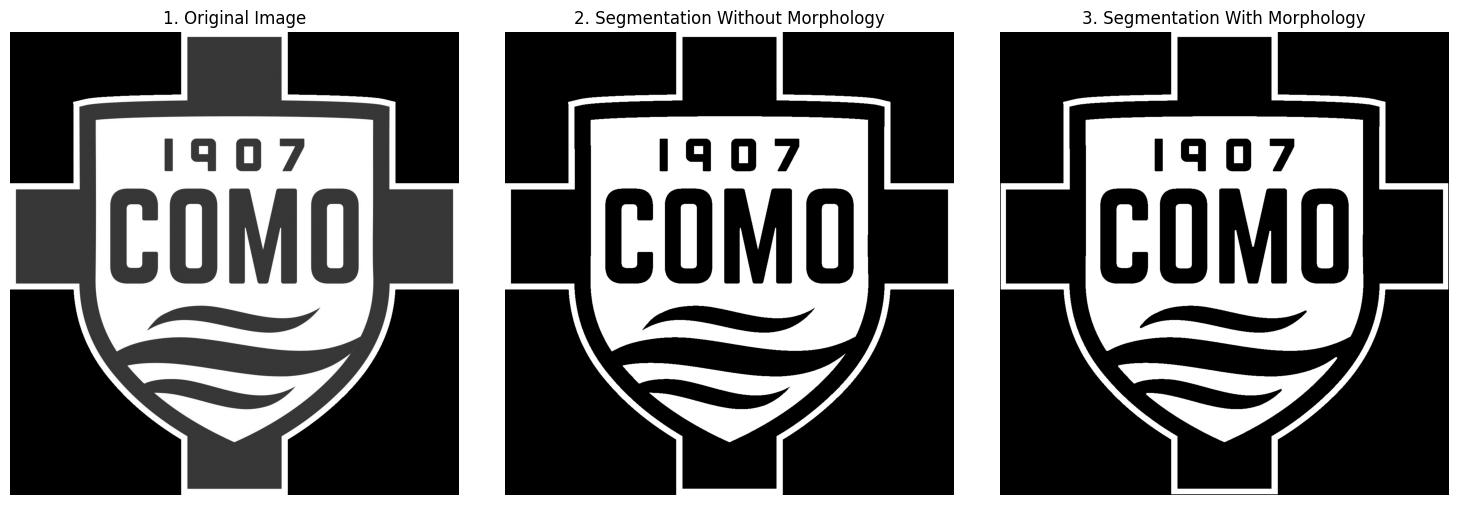

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_img, cmap='gray')
axes[0].set_title("1. Original Image")
axes[0].axis('off')

axes[1].imshow(segmented_img, cmap='gray')
axes[1].set_title("2. Segmentation Without Morphology")
axes[1].axis('off')

axes[2].imshow(img_final_morphology, cmap='gray')
axes[2].set_title("3. Segmentation With Morphology")
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Detailed Analysis and Experimental Results

### 1. Image Conversion & Preprocessing
The input image `image.jpg` was successfully converted from RGB to a single-channel grayscale representation using the custom weighted luminance formula ($Y = 0.299R + 0.587G + 0.114B$). This step eliminates color redundancy while preserving critical edge and intensity information needed for manual thresholding.

### 2. Manual Otsu Segmentation (Without Morphology)
Without leveraging external image processing libraries, the Otsu Thresholding algorithm was implemented from scratch. By computing the normalized intensity histogram and evaluating the between-class variance ($\sigma_b^2$) across all 256 gray levels, an optimal global threshold value was derived to separate the foreground (target object) from the background.

* **Observation**: Although global thresholding cleanly isolates high-contrast boundaries, the resulting binary image exhibits noticeable artifacts:
  * **Salt-and-pepper noise**: Isolated white background pixels or stray dark pixels within the main structure.
  * **Incomplete foreground masks**: Small internal gaps or structural holes caused by uneven illumination and local intensity variations.

### 3. Manual Morphological Processing
To refine the segmented binary mask, fundamental morphological operations were executed using a custom $5 \times 5$ square structuring element (kernel):
* **Opening Operation (Erosion $\rightarrow$ Dilation)**: Effectively removes small isolated white noise dots in the background without modifying the overall shape and boundary of the primary object.
* **Closing Operation (Dilation $\rightarrow$ Erosion)**: Fills small internal gaps and dark holes within the foreground object while smoothing out sharp concave boundaries.

---

## Conclusion

1. **Self-Implemented Algorithms**: The entire pipeline—ranging from RGB conversion and Otsu's automatic threshold selection to spatial kernel convolutions for morphological erosion and dilation—was successfully implemented using pure matrix operations via NumPy.
2. **Impact of Morphology**: Combining Otsu segmentation with consecutive Morphological Opening and Closing produces a significantly cleaner, continuous, and noise-free binary mask compared to applying thresholding alone.
3. **Practical Utility**: Morphological post-processing proves essential in computer vision workflows for preparing segmented masks before feature extraction, contour analysis, or object identification.